In [19]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
dataset= fetch_california_housing()

In [5]:
X= pd.DataFrame(dataset.data, columns= dataset.feature_names)
y= pd.Series(dataset.target)

In [8]:
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [10]:
X= X[['MedInc','AveRooms']] # taking two features

In [11]:
# train and test
X_train, X_test , y_train,y_test= train_test_split(X,y, train_size=0.2,random_state=42)

In [12]:
lr= LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [13]:
# slope and intercept
print('coeff/slope: ',lr.coef_)
print('intercept/bias: ',lr.intercept_)

coeff/slope:  [ 0.41744749 -0.01086541]
intercept/bias:  0.5152232501638396


in the above code we get the  array of coeff this is because we used two features for training the model (multiple regression). And making it 3 dimension plotting (slopes + target)

In [15]:
y_pred= lr.predict(X_test)

In [17]:
predictions= pd.DataFrame({'Actual':y_test, 'Predictated':y_pred})
predictions.head()

,Actual,Predictated
20046,0.47700,1.171486
3024,0.45800,1.517153
15663,5.00001,1.924769
20484,2.18600,2.843400
9814,2.78000,2.010532


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


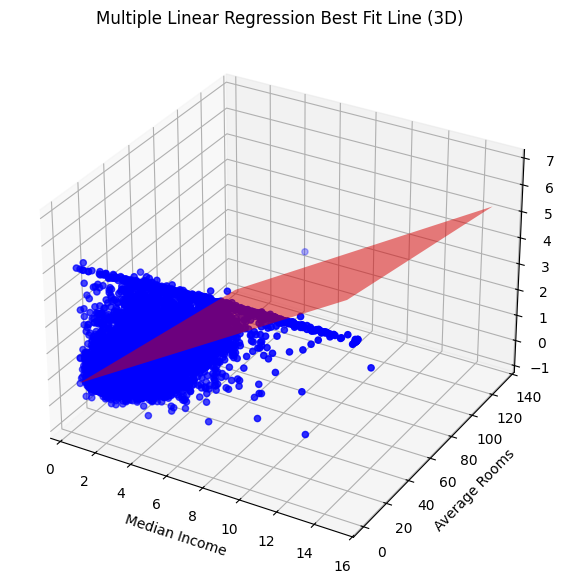

In [21]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_test['MedInc'], X_test['AveRooms'],
           y_test, color='blue', label='Actual Data')

x1_range = np.linspace(X_test['MedInc'].min(), X_test['MedInc'].max(), 100)
x2_range = np.linspace(X_test['AveRooms'].min(), X_test['AveRooms'].max(), 100)
x1, x2 = np.meshgrid(x1_range, x2_range)

z = lr.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)

ax.plot_surface(x1, x2, z, color='red', alpha=0.5, rstride=100, cstride=100)

ax.set_xlabel('Median Income')
ax.set_ylabel('Average Rooms')
ax.set_zlabel('House Price')
ax.set_title('Multiple Linear Regression Best Fit Line (3D)')

plt.show()